# STATE Codex R1 — Basal transcriptomic distance

**Question:** does STATE prediction error increase as a held-out cell line becomes less similar to the training-reference cell lines in baseline gene expression?

This notebook contains all analysis code in executable cells. Run the six sections from top to bottom: public data → processing → distance and levels → released predictions → curves and controls → the agent's decision. No custom Python modules, external analysis scripts, saved feature tables or saved result tables are needed. Data files may be stored on disk; derived quantities are recalculated on every Run All.

This is the **distance investigation only**. The target is the released **ST-HVG-Tahoe `eval_best.ckpt` zero-shot evaluation**. The audit did not fine-tune STATE or perform fresh inference. It analyzed the released predictions and observations.

Use **Python 3.11** with these standard packages (install once in the notebook environment):
```bash
python -m pip install numpy==1.26.4 pandas==2.2.2 scipy==1.13.1 statsmodels==0.14.2 pyarrow==16.1.0 matplotlib==3.9.4 ipython ipykernel
```
The 20 source downloads total about **7.66 GB**, plus extraction/output space. Existing raw downloads are checksum-verified before reuse. Set `STATE_DISTANCE_INPUTS` to use an existing raw-data directory, or leave the default and download the sources directly.


## 1. Data source/acquisition

Sources are fixed below, including direct download URLs, expected byte sizes and SHA-256 fingerprints:
- Cell Model Passports (CMP) RNA-seq, June 2022: primary input-side expression atlas.
- DepMap 23Q4 model metadata: cell-line names and identifiers; its expression table supplies the independent CCLE check.
- The released STATE cell-type map: reference-panel membership after excluding the five held-out contexts.
- Tahoe-100M cell metadata: observed cells per drug-dose condition.
- ST-HVG-Tahoe: observed/predicted fold changes and released condition-result files, pinned to one repository revision.

The source table is defined here, rather than loaded from a neighboring manifest. Existing raw files are checked before reuse. The downloader stops on a checksum mismatch.


In [1]:
from pathlib import Path
from collections import Counter, OrderedDict
from concurrent.futures import ThreadPoolExecutor
from io import BytesIO
import ast
import hashlib
import json
import math
import os
import pickle
import platform
import re
import shutil
import time
import urllib.parse
import urllib.request
import zipfile

# Keep numerical work bounded on the shared host.
for variable in ['OPENBLAS_NUM_THREADS', 'OMP_NUM_THREADS', 'MKL_NUM_THREADS']:
    os.environ[variable] = '1'
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import statsmodels.api as sm
from scipy.stats import spearmanr
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

# Optional: point this environment variable at an existing RAW input cache.
# No previously calculated feature, score or analysis files are read.
DATA_DIR = Path(os.environ.get('STATE_DISTANCE_INPUTS', 'state_distance_inputs')).expanduser().resolve()
OUTPUT_DIR = Path('state_distance_outputs').resolve()
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
STARTED = time.time()
CONTEXT_FILES = {'C32': 'C32', 'HOP62': 'HOP62', 'HepG2/C3A': 'HepG2-C3A',
                 'Hs 766T': 'Hs 766T', 'PANC-1': 'PANC-1'}
HELD_OUT = set(CONTEXT_FILES)
N_AXIS_GENES, K_NEIGHBORS = 2000, 5
BOOTSTRAP_REPS, RANDOM_SEED = 10000, 20260714
pd.set_option('display.max_colwidth', 110)
pd.set_option('display.max_rows', 100)


In [2]:
SOURCES = [{'path': 'acquisition/DepMap_Model_23Q4.csv',
  'url': 'https://ndownloader.figshare.com/files/43746708',
  'bytes': 530469,
  'sha256': '6b77a73209ce3faaa7442dbd947d8e08ddcb08b538c36fe820163f9cff321341'},
 {'path': 'acquisition/OmicsExpressionProteinCodingGenesTPMLogp1_23Q4.csv',
  'url': 'https://ndownloader.figshare.com/files/43347204',
  'bytes': 449782440,
  'sha256': 'd8e6eb9152c164e9bae49741fd46f5d4fd14c0d298c2a6de5d0996cb6cd3a6f8'},
 {'path': 'acquisition/cmp_rnaseq_all_20220624.zip',
  'url': 'https://cog.sanger.ac.uk/cmp/download/rnaseq_all_20220624.zip',
  'bytes': 940707972,
  'sha256': '2af6fd33a16c5c3d48a8d78976f54b4a09fcf0bac4102317b621f24d7bdca39a'},
 {'path': 'acquisition/tahoe_obs_metadata.parquet',
  'url': 'https://huggingface.co/datasets/tahoebio/Tahoe-100M/resolve/2dc57900b7981cfcf5e211527169a0b006546a95/metadata/obs_metadata.parquet',
  'bytes': 2293981573,
  'sha256': 'e51b24f3666f5f433c59ff01dd6fa33934627091455e89d929f2c1ddc87401fe'},
 {'path': 'acquisition/state_tahoe_cell_type_onehot_map_verified.pkl',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/cell_type_onehot_map.pkl',
  'bytes': 517889,
  'sha256': '44bbc9823979ec02a336d62651cf6918e3f6ce162e20b42f86eb06d7e872e20a'},
 {'path': 'acquisition/official_scores/C32_real_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_real_de.csv',
  'bytes': 387383572,
  'sha256': '19922ccec8820e43daa74dac907adeaa7b12d651308570650920762269f568d2'},
 {'path': 'acquisition/official_scores/HOP62_real_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_real_de.csv',
  'bytes': 395844167,
  'sha256': '05c3fa4a991b1e94cdd991be01a787bd779c384d66760b70fbd569ffe5411063'},
 {'path': 'acquisition/official_scores/HepG2-C3A_real_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_real_de.csv',
  'bytes': 381547673,
  'sha256': 'a038a095e74641cf068dc048a5e4f619b572c5b0b97ff9a10c47931ab75db13b'},
 {'path': 'acquisition/official_scores/Hs 766T_real_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs%20766T_real_de.csv',
  'bytes': 389336629,
  'sha256': '7d9f9e651c57a4ebb11ee04c256dac7a8b642b4736d3499c75cefa39908469d5'},
 {'path': 'acquisition/official_scores/PANC-1_real_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_real_de.csv',
  'bytes': 398029547,
  'sha256': '2b9ed18f2dae9d83dbfa910d9e7e2cac1da7ad0f73e43bed40b8daaf62a254c9'},
 {'path': 'acquisition/official_scores/C32_pred_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_pred_de.csv',
  'bytes': 399394066,
  'sha256': '58a5341d3e6b308c8eba7c82b45d4eb9dd140f9bf659bcb037eac647ce97e374'},
 {'path': 'acquisition/official_scores/C32_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/C32_results.csv',
  'bytes': 468117,
  'sha256': 'a0de78f621e8c6dfc67ac6ab6acbbab65fbd3aaddf7e56732ed6f03569d39f94'},
 {'path': 'acquisition/official_scores/HOP62_pred_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_pred_de.csv',
  'bytes': 406763875,
  'sha256': '1d8b2a07b60e751746854378effb7e8ba79cbd66446fa6c2d03acdeb328bbed4'},
 {'path': 'acquisition/official_scores/HOP62_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HOP62_results.csv',
  'bytes': 459434,
  'sha256': 'e3fef3287ccc5f38ac64c1c249915684a11dda7b38b43884b1f636cde792364a'},
 {'path': 'acquisition/official_scores/HepG2-C3A_pred_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_pred_de.csv',
  'bytes': 399787916,
  'sha256': 'b3ce247d0e2019fedd2f910af1c0f84c5f4ff0af1a854ac8e1c69e4975c1ba82'},
 {'path': 'acquisition/official_scores/HepG2-C3A_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/HepG2-C3A_results.csv',
  'bytes': 479496,
  'sha256': '8f953408f94eadc1461851599a33e2a4f84e413621d5ee54a52a8746c2037691'},
 {'path': 'acquisition/official_scores/Hs 766T_pred_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs%20766T_pred_de.csv',
  'bytes': 404556041,
  'sha256': 'a19eb583fb89f7152bf863e3681fe291e513f0ee65654b3ee55b1ad7ef1f009b'},
 {'path': 'acquisition/official_scores/Hs 766T_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/Hs%20766T_results.csv',
  'bytes': 466949,
  'sha256': 'b9ab34b3d93a414e5db0650aaad70fb9bc558abade0e4c4eb3322ab3e4a47080'},
 {'path': 'acquisition/official_scores/PANC-1_pred_de.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_pred_de.csv',
  'bytes': 407599726,
  'sha256': '11a225a6a6851507cec93ddf22b67df570f52cb3ce1b25cd60d46bc26fa03a5a'},
 {'path': 'acquisition/official_scores/PANC-1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt/PANC-1_results.csv',
  'bytes': 461203,
  'sha256': '2171a50b43d55ed6a5fae82c50685fd519b21b3a821872cb0e147a338d26a332'}]

CMP_MEMBER = {'path': 'acquisition/rnaseq_tpm_20220624.csv',
 'bytes': 257466286,
 'sha256': '54514510ffa03f3050e3787ab3d7f5a4d677068c4ed1a20177a7b57381d3a5bb',
 'archive_member': 'rnaseq_tpm_20220624.csv'}

source_table = pd.DataFrame(SOURCES)
assert source_table.path.is_unique
assert source_table.sha256.str.fullmatch('[0-9a-f]{64}').all()
display(source_table)
print(f'{len(SOURCES)} files; {source_table.bytes.sum()/1e9:.3f} GB of public source data')


,path,url,bytes,sha256
0,acquisition/DepMap_Model_23Q4.csv,https://ndownloader.figshare.com/files/43746708,530469,6b77a73209ce3faaa7442dbd947d8e08ddcb08b538c36fe820163f9cff321341
1,acquisition/OmicsExpressionProteinCodingGenesTPMLogp1_23Q4.csv,https://ndownloader.figshare.com/files/43347204,449782440,d8e6eb9152c164e9bae49741fd46f5d4fd14c0d298c2a6de5d0996cb6cd3a6f8
2,acquisition/cmp_rnaseq_all_20220624.zip,https://cog.sanger.ac.uk/cmp/download/rnaseq_all_20220624.zip,940707972,2af6fd33a16c5c3d48a8d78976f54b4a09fcf0bac4102317b621f24d7bdca39a
3,acquisition/tahoe_obs_metadata.parquet,https://huggingface.co/datasets/tahoebio/Tahoe-100M/resolve/2dc57900b7981cfcf5e211527169a0b006546a95/metad...,2293981573,e51b24f3666f5f433c59ff01dd6fa33934627091455e89d929f2c1ddc87401fe
4,acquisition/state_tahoe_cell_type_onehot_map_verified.pkl,https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot...,517889,44bbc9823979ec02a336d62651cf6918e3f6ce162e20b42f86eb06d7e872e20a
5,acquisition/official_scores/C32_real_de.csv,https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot...,387383572,19922ccec8820e43daa74dac907adeaa7b12d651308570650920762269f568d2
6,acquisition/official_scores/HOP62_real_de.csv,https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot...,395844167,05c3fa4a991b1e94cdd991be01a787bd779c384d66760b70fbd569ffe5411063
7,acquisition/official_scores/HepG2-C3A_real_de.csv,https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot...,381547673,a038a095e74641cf068dc048a5e4f619b572c5b0b97ff9a10c47931ab75db13b
8,acquisition/official_scores/Hs 766T_real_de.csv,https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot...,389336629,7d9f9e651c57a4ebb11ee04c256dac7a8b642b4736d3499c75cefa39908469d5
9,acquisition/official_scores/PANC-1_real_de.csv,https://huggingface.co/arcinstitute/ST-HVG-Tahoe/resolve/ca6b751972493f8448e3256d1340ae70ad43e1e7/zeroshot...,398029547,2b9ed18f2dae9d83dbfa910d9e7e2cac1da7ad0f73e43bed40b8daaf62a254c9


20 files; 7.658 GB of public source data


In [3]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def matches_source(path, source):
    return (path.is_file() and path.stat().st_size == source['bytes']
            and sha256_file(path) == source['sha256'])


def download_cmp_archive(source, path):
    """Fetch the large CMP archive in resumable 4-MB HTTP ranges."""
    pieces = path.with_name(path.name + '.ranges')
    pieces.mkdir(parents=True, exist_ok=True)
    block_size = 4 * 1024 * 1024
    spans = [(start, min(start + block_size, source['bytes']) - 1)
             for start in range(0, source['bytes'], block_size)]

    def fetch_piece(span):
        start, end = span
        piece = pieces / str(start)
        expected = end - start + 1
        if piece.is_file() and piece.stat().st_size == expected:
            return piece
        temporary = piece.with_name(piece.name + '.part')
        for attempt in range(6):
            try:
                request = urllib.request.Request(source['url'], headers={
                    'Range': f'bytes={start}-{end}', 'User-Agent': 'STATE-distance-notebook/1.0',
                })
                with urllib.request.urlopen(request, timeout=120) as response:
                    expected_range = f'bytes {start}-{end}/{source["bytes"]}'
                    if response.status != 206 or response.headers.get('Content-Range') != expected_range:
                        raise ValueError('CMP server did not honor the requested byte range')
                    with temporary.open('wb') as target:
                        shutil.copyfileobj(response, target, length=128 * 1024)
                if temporary.stat().st_size != expected:
                    raise ValueError('Incomplete CMP range')
                temporary.replace(piece)
                return piece
            except Exception:
                if attempt == 5:
                    raise
                time.sleep(min(10, 2 ** attempt))

    with ThreadPoolExecutor(max_workers=8) as pool:
        list(pool.map(fetch_piece, spans))
    assembled = path.with_name(path.name + '.assembled')
    with assembled.open('wb') as target:
        for start, _ in spans:
            with (pieces / str(start)).open('rb') as piece:
                shutil.copyfileobj(piece, target, length=8 * 1024 * 1024)
    if not matches_source(assembled, source):
        raise ValueError('Assembled CMP archive failed its declared checksum')
    assembled.replace(path)
    for start, _ in spans:
        (pieces / str(start)).unlink()
    pieces.rmdir()


def download_source(source):
    path = DATA_DIR / source['path']
    if matches_source(path, source):
        return {**source, 'status': 'verified existing raw file'}
    if path.exists():
        raise ValueError(f'Existing file differs from the declared source: {path}')
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.name == 'cmp_rnaseq_all_20220624.zip':
        download_cmp_archive(source, path)
        return {**source, 'status': 'downloaded in ranges and verified'}
    partial = path.with_name(path.name + '.download-part')
    parts = urllib.parse.urlsplit(source['url'])
    url = urllib.parse.urlunsplit(parts._replace(path=urllib.parse.quote(parts.path, safe='/%')))
    request = urllib.request.Request(url, headers={'User-Agent': 'STATE-distance-notebook/1.0'})
    with urllib.request.urlopen(request, timeout=120) as response, partial.open('wb') as target:
        if response.status != 200:
            raise ValueError(f'Unexpected download status: {response.status}')
        written = 0
        while True:
            block = response.read(1024 * 1024)
            if not block:
                break
            written += len(block)
            if written > source['bytes']:
                raise ValueError('Download exceeds the expected size')
            target.write(block)
    if not matches_source(partial, source):
        raise ValueError(f'Download size or checksum mismatch: {source["path"]}')
    partial.replace(path)
    return {**source, 'status': 'downloaded and verified'}

# Four I/O workers; this does not launch model inference.
with ThreadPoolExecutor(max_workers=4) as pool:
    download_receipts = list(pool.map(download_source, SOURCES))
display(pd.DataFrame(download_receipts)[['path', 'status', 'bytes']])

# Extract only the expression member used by this analysis.
cmp_archive = DATA_DIR / 'acquisition/cmp_rnaseq_all_20220624.zip'
cmp_path = DATA_DIR / CMP_MEMBER['path']
if not matches_source(cmp_path, CMP_MEMBER):
    with zipfile.ZipFile(cmp_archive) as archive:
        with archive.open(CMP_MEMBER['archive_member']) as source, cmp_path.open('wb') as destination:
            shutil.copyfileobj(source, destination, length=8 * 1024 * 1024)
if not matches_source(cmp_path, CMP_MEMBER):
    raise ValueError('Extracted CMP expression table failed verification')
print('All 20 raw files and the CMP expression member are verified.')


,path,status,bytes
0,acquisition/DepMap_Model_23Q4.csv,verified existing raw file,530469
1,acquisition/OmicsExpressionProteinCodingGenesTPMLogp1_23Q4.csv,verified existing raw file,449782440
2,acquisition/cmp_rnaseq_all_20220624.zip,verified existing raw file,940707972
3,acquisition/tahoe_obs_metadata.parquet,verified existing raw file,2293981573
4,acquisition/state_tahoe_cell_type_onehot_map_verified.pkl,verified existing raw file,517889
5,acquisition/official_scores/C32_real_de.csv,verified existing raw file,387383572
6,acquisition/official_scores/HOP62_real_de.csv,verified existing raw file,395844167
7,acquisition/official_scores/HepG2-C3A_real_de.csv,verified existing raw file,381547673
8,acquisition/official_scores/Hs 766T_real_de.csv,verified existing raw file,389336629
9,acquisition/official_scores/PANC-1_real_de.csv,verified existing raw file,398029547


All 20 raw files and the CMP expression member are verified.


## 2. Data processing

First decode the cell names from the public STATE map, join them to DepMap/Sanger identifiers, and load the relevant expression rows. The map's tensor values are unnecessary; the restricted decoder below reads their keys without loading a neural model.

Cell-name aliases are resolved before looking at prediction errors. The explicit name fixes are C3A for HepG2/C3A, PANC0327 for Panc 03.27, and DepMap ID ACH-000396 for J82. Unresolved held-out cell lines stop execution.


In [4]:
MANUAL_DEPMAP_NAMES = {'HepG2/C3A': 'C3A', 'Panc 03.27': 'PANC0327'}
MANUAL_DEPMAP_IDS = {'J82': 'ACH-000396'}


def ignore_tensor_payload(*args):
    return None


class CellMapKeysUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        allowed = {
            ('torch._utils', '_rebuild_tensor_v2'): ignore_tensor_payload,
            ('torch.storage', '_load_from_bytes'): ignore_tensor_payload,
            ('collections', 'OrderedDict'): OrderedDict,
            ('numpy', 'dtype'): np.dtype,
            ('numpy._core.multiarray', 'scalar'): np.core.multiarray.scalar,
            ('numpy.core.multiarray', 'scalar'): np.core.multiarray.scalar,
        }
        if (module, name) not in allowed:
            raise pickle.UnpicklingError(f'Unexpected cell-map object: {module}.{name}')
        return allowed[(module, name)]
def normalize_name(value: object) -> str:
    return re.sub(r"[^A-Z0-9]", "", str(value).upper())

def build_alias_index(sample_info: pd.DataFrame) -> dict[str, set[str]]:
    fields = ["stripped_cell_line_name", "CCLE_Name", "Alias"]
    index: dict[str, set[str]] = {}
    for _, row in sample_info.iterrows():
        depmap_id = row["DepMap_ID"]
        if pd.isna(depmap_id):
            continue
        values: list[str] = []
        for field in fields:
            value = row.get(field)
            if pd.isna(value):
                continue
            values.extend(re.split(r"[,;/|]", str(value)))
            if field == "CCLE_Name":
                values.append(str(value).split("_")[0])
        for value in values:
            key = normalize_name(value)
            if key:
                index.setdefault(key, set()).add(str(depmap_id))
    return index

def map_cell_lines(cell_lines: list[str], sample_info: pd.DataFrame) -> pd.DataFrame:
    alias_index = build_alias_index(sample_info)
    rows = []
    for cell in cell_lines:
        lookup = MANUAL_DEPMAP_NAMES.get(cell, cell)
        candidates = (
            [MANUAL_DEPMAP_IDS[cell]]
            if cell in MANUAL_DEPMAP_IDS
            else sorted(alias_index.get(normalize_name(lookup), set()))
        )
        status = "exact" if len(candidates) == 1 else "ambiguous" if candidates else "unmatched"
        depmap_id = candidates[0] if len(candidates) == 1 else None
        rows.append(
            {
                "cell_line": cell,
                "held_out": cell in HELD_OUT,
                "lookup_name": lookup,
                "depmap_id": depmap_id,
                "match_status": status,
                "candidate_ids": "|".join(candidates),
            }
        )
    mapping = pd.DataFrame(rows)
    details = sample_info[
        [
            "DepMap_ID",
            "stripped_cell_line_name",
            "CCLE_Name",
            "Sanger_Model_ID",
            "lineage",
            "lineage_subtype",
        ]
    ].drop_duplicates("DepMap_ID")
    return mapping.merge(details, left_on="depmap_id", right_on="DepMap_ID", how="left")


In [5]:
cell_map_path = DATA_DIR / 'acquisition/state_tahoe_cell_type_onehot_map_verified.pkl'
with cell_map_path.open('rb') as stream:
    cell_lines = sorted(map(str, CellMapKeysUnpickler(stream).load().keys()))
sample_info = pd.read_csv(DATA_DIR / 'acquisition/DepMap_Model_23Q4.csv', low_memory=False)
sample_info = sample_info.rename(columns={
    'ModelID': 'DepMap_ID', 'StrippedCellLineName': 'stripped_cell_line_name',
    'CCLEName': 'CCLE_Name', 'CellLineName': 'Alias', 'SangerModelID': 'Sanger_Model_ID',
    'OncotreeLineage': 'lineage', 'OncotreeSubtype': 'lineage_subtype',
})
mapping = map_cell_lines(cell_lines, sample_info)
assert mapping.cell_line.is_unique
unresolved = mapping[mapping.held_out & mapping.match_status.ne('exact')]
if not unresolved.empty:
    raise ValueError('Unresolved held-out cell mappings: ' + unresolved.to_string(index=False))
train_map = mapping[(~mapping.held_out) & mapping.depmap_id.notna()].copy()
test_map = mapping[mapping.held_out].copy()
display(mapping[['cell_line', 'held_out', 'depmap_id', 'Sanger_Model_ID', 'match_status']])
print('Mapped reference contexts:', len(train_map), '| Held-out contexts:', len(test_map))


,cell_line,held_out,depmap_id,Sanger_Model_ID,match_status
0,A-172,False,ACH-000558,SIDM00799,exact
1,A-427,False,ACH-000757,SIDM00810,exact
2,A498,False,ACH-000555,SIDM00124,exact
3,A549,False,ACH-000681,SIDM00903,exact
4,AN3 CA,False,ACH-000940,SIDM00901,exact
5,AsPC-1,False,ACH-000222,SIDM00899,exact
6,BT-474,False,ACH-000927,SIDM00963,exact
7,C-33 A,False,ACH-001333,SIDM00889,exact
8,C32,True,ACH-000580,SIDM00890,exact
9,CFPAC-1,False,ACH-000138,SIDM00130,exact


Mapped reference contexts: 44 | Held-out contexts: 5


In [6]:
def load_cmp_subset(path: Path, sanger_ids: list[str]) -> pd.DataFrame:
    usecols = ["model_id", "Unnamed: 1", *sanger_ids]
    data = pd.read_csv(path, usecols=usecols, low_memory=False)
    data = data.iloc[4:].copy()
    genes = data.pop("Unnamed: 1").astype(str)
    data = data.drop(columns="model_id")
    data.index = genes
    data = data[~data.index.duplicated(keep="first")]
    data = data.apply(pd.to_numeric, errors="coerce").T
    return np.log2(data + 1.0)

# CMP's first four metadata rows are removed inside load_cmp_subset.
# Remaining TPM values are numeric, duplicate gene symbols keep their first row,
# and expression is transformed to log2(TPM + 1).
sanger_ids = mapping.Sanger_Model_ID.dropna().astype(str).tolist()
cmp_expression = load_cmp_subset(cmp_path, sanger_ids)

# DepMap's expression table is already log-transformed by its publisher.
ccle_expression = pd.read_csv(
    DATA_DIR / 'acquisition/OmicsExpressionProteinCodingGenesTPMLogp1_23Q4.csv',
    index_col=0, low_memory=False,
)
ccle_expression.columns = [re.sub(r'\s*\(\d+\)$', '', str(name)) for name in ccle_expression.columns]
ccle_expression = ccle_expression.loc[:, ~ccle_expression.columns.duplicated()].astype(float)
print('Processed CMP shape:', cmp_expression.shape)
print('Processed CCLE shape:', ccle_expression.shape)


Processed CMP shape: (49, 37600)
Processed CCLE shape: (1479, 19193)


Count observed cells for each held-out context × drug-dose condition. These counts later control for unequal sampling. A positive `full` QC count is used where available; otherwise the total observed count is used. This scan reads only the three required metadata columns.


In [7]:
observation_data = ds.dataset(DATA_DIR / 'acquisition/tahoe_obs_metadata.parquet', format='parquet')
scanner = observation_data.scanner(
    columns=['cell_name', 'drugname_drugconc', 'pass_filter'],
    filter=ds.field('cell_name').isin(list(CONTEXT_FILES)), batch_size=500000,
)
all_counts, full_counts = Counter(), Counter()
for batch in scanner.to_batches():
    batch_frame = batch.to_pandas()
    all_counts.update(zip(batch_frame.cell_name, batch_frame.drugname_drugconc))
    full = batch_frame[batch_frame.pass_filter.astype(str).str.lower().eq('full')]
    full_counts.update(zip(full.cell_name, full.drugname_drugconc))
cell_counts = pd.DataFrame([
    {'cell_line': cell, 'target': target, 'n_cells_all': count,
     'n_cells_full': full_counts.get((cell, target), 0)}
    for (cell, target), count in all_counts.items()
]).sort_values(['cell_line', 'target'])
assert not cell_counts.duplicated(['cell_line', 'target']).any()
assert (cell_counts.n_cells_full <= cell_counts.n_cells_all).all()
display(cell_counts.head(10))
display(cell_counts.groupby('cell_line')[['n_cells_all', 'n_cells_full']].sum())


,cell_line,target,n_cells_all,n_cells_full
3655,C32,"[('(R)-Verapamil (hydrochloride)', 0.05, 'uM')]",2180,2095
4110,C32,"[('(R)-Verapamil (hydrochloride)', 0.5, 'uM')]",1233,1077
1937,C32,"[('(R)-Verapamil (hydrochloride)', 5.0, 'uM')]",4124,4029
4565,C32,"[('(S)-Crizotinib', 0.05, 'uM')]",1974,1835
4965,C32,"[('(S)-Crizotinib', 0.5, 'uM')]",1445,1347
5370,C32,"[('(S)-Crizotinib', 5.0, 'uM')]",1015,964
3719,C32,"[('18β-Glycyrrhetinic acid', 0.05, 'uM')]",1234,1139
4178,C32,"[('18β-Glycyrrhetinic acid', 0.5, 'uM')]",1011,875
1998,C32,"[('18β-Glycyrrhetinic acid', 5.0, 'uM')]",2641,2474
2610,C32,"[('4EGI-1', 0.05, 'uM')]",1405,1380


,n_cells_all,n_cells_full
cell_line,,
C32,2098357,1991252
HOP62,3420378,3307302
HepG2/C3A,1355321,1244192
Hs 766T,2742987,2535736
PANC-1,4170586,4089586


## 3. Axis definition and level construction

Select **2,000 genes with the highest sample variance across mapped training-reference CMP cell lines**. Standardize each gene using only those reference lines' mean and sample standard deviation. For a test line, calculate the root-mean-square standardized expression difference to every reference line, then take the **median distance to its five nearest reference lines**.

Larger values mean more distant baseline expression. The five held-out contexts become levels 1–5 by increasing distance. These 2,000 **axis genes** are selected independently of the released model's **evaluation features**; the two sets need not be the same.


In [8]:
def choose_primary_genes(
    expression: pd.DataFrame, train_ids: list[str], n_genes: int
) -> tuple[pd.DataFrame, list[str]]:
    renamed = {}
    for column in expression.columns:
        match = re.match(r"^(.+?)\s*\(\d+\)$", str(column))
        renamed[column] = match.group(1) if match else str(column)
    expression = expression.rename(columns=renamed)
    expression = expression.loc[:, ~expression.columns.duplicated()].astype(float)
    available_train = [value for value in train_ids if value in expression.index]
    variance = expression.loc[available_train].var(axis=0, ddof=1)
    genes = variance.sort_values(ascending=False).head(n_genes).index.tolist()
    return expression.loc[:, genes], genes

def panel_distance(
    expression: pd.DataFrame,
    train_ids: list[str],
    test_ids: list[str],
    k: int,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    train = expression.loc[train_ids]
    test = expression.loc[test_ids]
    means = train.mean(axis=0)
    scales = train.std(axis=0, ddof=1).replace(0, np.nan)
    valid = scales.notna() & np.isfinite(scales)
    train_z = (train.loc[:, valid] - means[valid]) / scales[valid]
    test_z = (test.loc[:, valid] - means[valid]) / scales[valid]
    pairwise = np.sqrt(
        ((test_z.to_numpy()[:, None, :] - train_z.to_numpy()[None, :, :]) ** 2).mean(axis=2)
    )
    pairwise_df = pd.DataFrame(pairwise, index=test_ids, columns=train_ids)
    k_eff = min(k, len(train_ids))
    summary = pd.DataFrame(
        {
            "sample_id": test_ids,
            "distance": np.median(np.sort(pairwise, axis=1)[:, :k_eff], axis=1),
            "nearest_distance": pairwise.min(axis=1),
            "nearest_training_id": pairwise_df.idxmin(axis=1).to_numpy(),
            "n_genes": int(valid.sum()),
            "n_training_contexts": len(train_ids),
            "k_neighbors": k_eff,
        }
    )
    return summary, pairwise_df


In [9]:
train_sanger = train_map.loc[train_map.Sanger_Model_ID.isin(cmp_expression.index), 'Sanger_Model_ID'].astype(str).tolist()
test_sanger = test_map.loc[test_map.Sanger_Model_ID.isin(cmp_expression.index), 'Sanger_Model_ID'].astype(str).tolist()
assert len(test_sanger) == len(HELD_OUT), 'CMP is missing a held-out context'
cmp_selected, axis_genes = choose_primary_genes(cmp_expression, train_sanger, N_AXIS_GENES)
primary, primary_pairwise = panel_distance(cmp_selected, train_sanger, test_sanger, K_NEIGHBORS)
primary = primary.merge(
    test_map[['cell_line', 'depmap_id', 'Sanger_Model_ID']],
    left_on='sample_id', right_on='Sanger_Model_ID', validate='one_to_one',
).drop(columns='sample_id').sort_values('distance')
primary['level'] = np.arange(1, len(primary) + 1)
display(primary[['level', 'cell_line', 'distance', 'nearest_training_id', 'n_genes', 'n_training_contexts']])
print('Selected axis genes:', len(axis_genes))
display(pd.DataFrame({'axis_gene': axis_genes}))


,level,cell_line,distance,nearest_training_id,n_genes,n_training_contexts
1,1,HOP62,0.953059,SIDM00693,2000,44
4,2,PANC-1,1.062149,SIDM00138,2000,44
3,3,Hs 766T,1.131635,SIDM01138,2000,44
0,4,C32,1.254312,SIDM00082,2000,44
2,5,HepG2/C3A,1.404170,SIDM00840,2000,44


Selected axis genes: 2000


,axis_gene
0,MIR6087
1,KRT19
2,VIM
3,SPARC
4,RPS4Y1
...,...
1995,PADI3
1996,PRSS12
1997,HDAC9
1998,CYP4F12


The independent CCLE check reuses the CMP-selected gene symbols available in CCLE and refits scaling on its training-reference lines. HepG2/C3A lacks a CCLE expression row, so the declared parental HepG2 proxy (ACH-000739) is used. Section 5 also repeats the adjusted fit with that proxy context excluded.


In [10]:
ccle_genes = [gene for gene in axis_genes if gene in ccle_expression.columns]
train_ccle = [cell for cell in train_map.depmap_id.astype(str) if cell in ccle_expression.index]
test_ccle_map = test_map[['cell_line', 'depmap_id']].copy()
test_ccle_map['proxy_used'] = test_ccle_map.cell_line.eq('HepG2/C3A')
test_ccle_map.loc[test_ccle_map.proxy_used, 'depmap_id'] = 'ACH-000739'
assert set(test_ccle_map.depmap_id).issubset(ccle_expression.index)
independent, independent_pairwise = panel_distance(
    ccle_expression.loc[:, ccle_genes], train_ccle, test_ccle_map.depmap_id.tolist(), K_NEIGHBORS,
)
independent = independent.merge(test_ccle_map, left_on='sample_id', right_on='depmap_id', validate='one_to_one')
independent = independent.drop(columns='sample_id').sort_values('distance')
independent['level'] = np.arange(1, len(independent) + 1)
display(independent[['level', 'cell_line', 'distance', 'proxy_used', 'n_genes', 'n_training_contexts']])
atlas_check = primary[['cell_line', 'distance']].merge(
    independent[['cell_line', 'distance']], on='cell_line', suffixes=('_cmp', '_ccle'), validate='one_to_one',
)
print('CMP/CCLE distance-rank correlation:', spearmanr(atlas_check.distance_cmp, atlas_check.distance_ccle).statistic)


,level,cell_line,distance,proxy_used,n_genes,n_training_contexts
1,1,HOP62,0.995532,False,1832,43
4,2,PANC-1,1.087685,False,1832,43
3,3,Hs 766T,1.196330,False,1832,43
0,4,C32,1.264095,False,1832,43
2,5,HepG2/C3A,1.363152,True,1832,43


CMP/CCLE distance-rank correlation: 0.9999999999999999


Construct the analysis population from released **condition identities**, before reading performance values. Keep drug-dose targets present in all five contexts and compounds with at least two doses. A fixed hash of the normalized parent compound puts all its doses/contexts into either discovery (buckets 0–2) or confirmation (3–9).

Distance is standardized using its mean/sample SD across all released condition rows **before eligibility filtering**. Dose and leave-one-context-out controls retain that scale.


In [11]:
def parse_target(value: str) -> tuple[str, float, str]:
    parsed = ast.literal_eval(value)
    if not isinstance(parsed, list) or len(parsed) != 1 or len(parsed[0]) != 3:
        raise ValueError(f"Unexpected Tahoe target: {value}")
    name, dose, unit = parsed[0]
    return str(name), float(dose), str(unit)

def normalize_compound(value: str) -> str:
    return re.sub(r"[^a-z0-9]+", "", value.lower())

def partition_for(compound: str) -> str:
    bucket = int(hashlib.sha256(compound.encode("utf-8")).hexdigest()[:16], 16) % 10
    return "discovery" if bucket <= 2 else "confirmation"

condition_frames = []
for cell, stem in CONTEXT_FILES.items():
    identities = pd.read_csv(DATA_DIR / f'acquisition/official_scores/{stem}_results.csv', usecols=['perturbation'])
    identities = identities.rename(columns={'perturbation': 'target'})
    assert identities.target.is_unique
    condition_frames.append(identities.assign(cell_line=cell))
all_conditions = pd.concat(condition_frames, ignore_index=True)
all_conditions = all_conditions.merge(primary[['cell_line', 'distance', 'level']], on='cell_line', validate='many_to_one')
all_conditions = all_conditions.merge(
    independent[['cell_line', 'distance', 'proxy_used']].rename(columns={'distance': 'ccle_distance'}),
    on='cell_line', validate='many_to_one',
)
all_conditions = all_conditions.merge(cell_counts, on=['cell_line', 'target'], how='left', validate='one_to_one')
parsed = all_conditions.target.map(parse_target)
all_conditions['compound_name'] = parsed.map(lambda x: x[0])
all_conditions['dose'] = parsed.map(lambda x: x[1])
all_conditions['dose_unit'] = parsed.map(lambda x: x[2])
all_conditions['compound'] = all_conditions.compound_name.map(normalize_compound)
all_conditions['partition'] = all_conditions.compound.map(partition_for)
all_conditions['n_cells'] = all_conditions.n_cells_full.where(all_conditions.n_cells_full > 0, all_conditions.n_cells_all)
all_conditions['log_n_cells'] = np.log1p(all_conditions.n_cells)
for column, standardized in [('distance', 'distance_z'), ('ccle_distance', 'ccle_distance_z')]:
    all_conditions[standardized] = (all_conditions[column] - all_conditions[column].mean()) / all_conditions[column].std(ddof=1)
coverage = all_conditions.groupby('target').cell_line.nunique()
common = all_conditions[all_conditions.target.isin(coverage[coverage == len(HELD_OUT)].index)].copy()
eligibility = common.groupby('compound').agg(
    n_contexts=('cell_line', 'nunique'), n_doses=('dose', 'nunique'),
    n_targets=('target', 'nunique'), partition=('partition', 'first'),
)
eligible_compounds = eligibility.index[(eligibility.n_contexts == len(HELD_OUT)) & (eligibility.n_doses >= 2)]
conditions = common[common.compound.isin(eligible_compounds)].copy()
assert conditions.n_cells.notna().all()
assert conditions.groupby('compound').partition.nunique().max() == 1
display(eligibility.head(12))
display(conditions.groupby('partition').agg(rows=('target', 'size'), targets=('target', 'nunique'),
    compounds=('compound', 'nunique'), contexts=('cell_line', 'nunique')))


,n_contexts,n_doses,n_targets,partition
compound,,,,
18glycyrrhetinicacid,5,3,3,discovery
4egi1,5,3,3,discovery
5azacytidine,5,3,3,confirmation
5fluorouracil,5,3,3,confirmation
8hydroxyquinoline,5,3,3,confirmation
9ing41,5,3,3,confirmation
abemaciclib,5,3,3,discovery
abirateroneacetate,5,3,3,confirmation
acetazolamide,5,3,3,discovery


,rows,targets,compounds,contexts
partition,,,,
confirmation,4020,804,268,5
discovery,1660,332,111,5


## 4. Model results or released scores

**Model:** Arc Institute ST-HVG-Tahoe, `zeroshot/state_generalization_zeroshot_X_hvg/eval_best.ckpt`, repository revision `ca6b751972493f8448e3256d1340ae70ad43e1e7`.

**Audit-specific fine-tuning: none. Fresh inference in this audit: none.** The acquisition cells downloaded its released prediction/observation tables and condition-result files. The code below calculates errors directly from those individual gene-level rows. Upstream model training is described in the [official STATE repository](https://github.com/ArcInstitute/state); the analysis below uses the released outputs.

For every drug-dose target, align observed and predicted `target`/`feature` rows, convert fold changes to log2, and calculate:
- STATE error: square root of the mean squared predicted-minus-observed log2 fold change.
- No-effect/identity-reference error: square root of the mean squared observed log2 fold change (prediction = zero change).
- Differential-expression count: number of observed features with FDR < 0.05, for the effect/sampling controls.

RMSE uses all **2,000 released evaluation features** for each target, including nonsignificant features.


In [12]:
def compute_lfc_scores(real_path: Path, pred_path: Path, chunksize: int = 250_000) -> pd.DataFrame:
    use_real = ["target", "feature", "fold_change", "fdr"]
    use_pred = ["target", "feature", "fold_change"]
    real_iter = pd.read_csv(real_path, usecols=use_real, chunksize=chunksize)
    pred_iter = pd.read_csv(pred_path, usecols=use_pred, chunksize=chunksize)
    accum: dict[str, list[float]] = {}
    total_rows = 0
    for real, pred in zip(real_iter, pred_iter, strict=True):
        if len(real) != len(pred):
            raise RuntimeError("real/pred DE chunk length mismatch")
        if not np.array_equal(real["target"].to_numpy(), pred["target"].to_numpy()):
            raise RuntimeError("real/pred DE target order mismatch")
        if not np.array_equal(real["feature"].to_numpy(), pred["feature"].to_numpy()):
            raise RuntimeError("real/pred DE feature order mismatch")
        real_lfc = np.log2(real["fold_change"].to_numpy(dtype=float))
        pred_lfc = np.log2(pred["fold_change"].to_numpy(dtype=float))
        if not (np.isfinite(real_lfc).all() and np.isfinite(pred_lfc).all()):
            raise RuntimeError("non-finite released fold change encountered")
        temp = pd.DataFrame(
            {
                "target": real["target"].to_numpy(),
                "state_sq": (pred_lfc - real_lfc) ** 2,
                "identity_sq": real_lfc**2,
                "is_de": real["fdr"].to_numpy(dtype=float) < 0.05,
                "n": 1,
            }
        )
        grouped = temp.groupby("target", sort=False).agg(
            state_sse=("state_sq", "sum"),
            identity_sse=("identity_sq", "sum"),
            n_de=("is_de", "sum"),
            n_genes=("n", "sum"),
        )
        for target, row in grouped.iterrows():
            current = accum.setdefault(target, [0.0, 0.0, 0.0, 0.0])
            current[0] += float(row["state_sse"])
            current[1] += float(row["identity_sse"])
            current[2] += float(row["n_de"])
            current[3] += float(row["n_genes"])
        total_rows += len(real)
    result = pd.DataFrame(
        [
            {
                "target": target,
                "state_lfc_rmse": math.sqrt(values[0] / values[3]),
                "identity_lfc_rmse": math.sqrt(values[1] / values[3]),
                "n_de": int(values[2]),
                "n_genes_lfc": int(values[3]),
            }
            for target, values in accum.items()
        ]
    )
    if int(result["n_genes_lfc"].sum()) != total_rows:
        raise RuntimeError("DE row accounting mismatch")
    return result


In [13]:
score_frames = []
for cell, stem in CONTEXT_FILES.items():
    print('Calculating released gene-level errors:', cell, flush=True)
    per_target = compute_lfc_scores(
        DATA_DIR / f'acquisition/official_scores/{stem}_real_de.csv',
        DATA_DIR / f'acquisition/official_scores/{stem}_pred_de.csv',
    )
    published = pd.read_csv(DATA_DIR / f'acquisition/official_scores/{stem}_results.csv')
    assert set(per_target.target) == set(published.perturbation)
    assert per_target.target.is_unique and per_target.n_genes_lfc.eq(2000).all()
    score_frames.append(per_target.assign(cell_line=cell))
scored_rows = pd.concat(score_frames, ignore_index=True)
conditions = conditions.merge(scored_rows, on=['cell_line', 'target'], validate='one_to_one')
conditions['log_n_de'] = np.log1p(conditions.n_de)
CONTROLS = ['identity_lfc_rmse', 'log_n_de', 'log_n_cells']
assert np.isfinite(conditions[['state_lfc_rmse', 'distance_z', *CONTROLS]].to_numpy()).all()
confirm = conditions[conditions.partition.eq('confirmation')].copy()
display(conditions[['cell_line', 'compound', 'dose', 'partition', 'level', 'distance',
                    'state_lfc_rmse', 'identity_lfc_rmse', 'n_de', 'n_cells']].head(12))
print('Scored target-context records:', len(scored_rows))
print('Observed/predicted feature pairs evaluated:', int(scored_rows.n_genes_lfc.sum()))
print('Confirmation rows / targets / compounds:', len(confirm), confirm.target.nunique(), confirm.compound.nunique())


Calculating released gene-level errors: C32


Calculating released gene-level errors: HOP62


Calculating released gene-level errors: HepG2/C3A


Calculating released gene-level errors: Hs 766T


Calculating released gene-level errors: PANC-1


,cell_line,compound,dose,partition,level,distance,state_lfc_rmse,identity_lfc_rmse,n_de,n_cells
0,C32,rverapamilhydrochloride,0.05,discovery,4,1.254312,1.956152,1.743597,320,2095
1,C32,rverapamilhydrochloride,0.50,discovery,4,1.254312,2.236865,2.060241,427,1077
2,C32,rverapamilhydrochloride,5.00,discovery,4,1.254312,1.716199,1.415155,531,4029
3,C32,scrizotinib,0.05,confirmation,4,1.254312,1.947983,1.950492,526,1835
4,C32,scrizotinib,0.50,confirmation,4,1.254312,2.034995,2.000006,220,1347
5,C32,scrizotinib,5.00,confirmation,4,1.254312,2.173920,2.117408,283,964
6,C32,18glycyrrhetinicacid,0.05,discovery,4,1.254312,2.204911,2.079753,306,1139
7,C32,18glycyrrhetinicacid,0.50,discovery,4,1.254312,2.301442,2.134732,341,875
8,C32,18glycyrrhetinicacid,5.00,discovery,4,1.254312,1.907020,1.683020,310,2474
9,C32,4egi1,0.05,discovery,4,1.254312,2.272496,1.918225,489,1380


Scored target-context records: 5684
Observed/predicted feature pairs evaluated: 11368000
Confirmation rows / targets / compounds: 4020 804 268


## 5. Curves and controls

The primary fit compares contexts **within the same drug-dose target** by centering the outcome and predictors within target. Standard errors cluster by parent compound. Positive slopes would support the proposed worsening with distance; negative slopes indicate lower error at greater distance.

The adjusted fit includes the no-effect reference error (effect magnitude), log(1 + DE-feature count) and log(1 + observed-cell count). The three fits below are run on discovery, confirmation and their union. Bootstrap uncertainty resamples parent compounds 10,000 times; STATE and reference use identical compound resamples for their paired slope contrast.


In [14]:
def within_design(frame: pd.DataFrame, outcome: str, controls: list[str]) -> tuple[np.ndarray, np.ndarray, list[str]]:
    names = ["distance_z", *controls]
    work = frame[["target", outcome, *names]].copy()
    for column in names:
        sd = work[column].std(ddof=1)
        if column != "distance_z" and sd > 0:
            work[column] = (work[column] - work[column].mean()) / sd
    centered = work.groupby("target", sort=False)[[outcome, *names]].transform(lambda x: x - x.mean())
    return centered[outcome].to_numpy(float), centered[names].to_numpy(float), names

def fit_within(frame: pd.DataFrame, outcome: str, controls: list[str]) -> dict:
    y, x, names = within_design(frame, outcome, controls)
    fit = sm.OLS(y, x).fit(cov_type="cluster", cov_kwds={"groups": frame["compound"].to_numpy()})
    idx = names.index("distance_z")
    estimate = float(fit.params[idx])
    p_two = float(fit.pvalues[idx])
    p_one = p_two / 2 if estimate >= 0 else 1 - p_two / 2
    return {
        "estimate": estimate,
        "se_cluster": float(fit.bse[idx]),
        "p_one_sided": p_one,
        "p_two_sided": p_two,
        "n_rows": len(frame),
        "n_targets": frame["target"].nunique(),
        "n_compounds": frame["compound"].nunique(),
        "controls": controls,
    }


In [15]:
def bootstrap_slopes(frame, outcome, controls, reps=BOOTSTRAP_REPS, seed=RANDOM_SEED):
    y, x, names = within_design(frame, outcome, controls)
    compound_ids = frame.compound.to_numpy()
    unique = np.unique(compound_ids)
    cross_products = np.stack([x[compound_ids == c].T @ x[compound_ids == c] for c in unique])
    responses = np.stack([x[compound_ids == c].T @ y[compound_ids == c] for c in unique])
    rng = np.random.default_rng(seed)
    slopes = np.empty(reps)
    axis_index = names.index('distance_z')
    for start in range(0, reps, 512):
        count = min(512, reps - start)
        multiplicities = rng.multinomial(len(unique), np.full(len(unique), 1 / len(unique)), size=count)
        lhs = np.einsum('bg,gij->bij', multiplicities, cross_products, optimize=True)
        rhs = np.einsum('bg,gi->bi', multiplicities, responses, optimize=True)
        # Rank-aware least squares also handles a collinear bootstrap draw.
        inverse = np.linalg.pinv(lhs, rcond=np.finfo(float).eps * lhs.shape[-1])
        slopes[start:start + count] = np.einsum('bij,bj->bi', inverse, rhs)[:, axis_index]
    return slopes


def fit_with_interval(frame, outcome, controls):
    result = fit_within(frame, outcome, controls)
    draws = bootstrap_slopes(frame, outcome, controls)
    result['ci_low'], result['ci_high'] = map(float, np.quantile(draws, [.025, .975]))
    return result, draws


model_specs = [('state_raw', 'state_lfc_rmse', []),
               ('state_adjusted', 'state_lfc_rmse', CONTROLS),
               ('identity_raw', 'identity_lfc_rmse', [])]
fit_results, fit_draws, fit_rows = {}, {}, []
for partition in ['discovery', 'confirmation', 'all']:
    subset = conditions if partition == 'all' else conditions[conditions.partition.eq(partition)]
    for name, outcome, controls in model_specs:
        result, draws = fit_with_interval(subset, outcome, controls)
        fit_results[(partition, name)] = result
        fit_draws[(partition, name)] = draws
        fit_rows.append({'partition': partition, 'model': name, **result})
fits = pd.DataFrame(fit_rows)
display(fits[['partition', 'model', 'estimate', 'ci_low', 'ci_high', 'n_rows', 'n_compounds']])
paired_draws = fit_draws[('confirmation', 'state_raw')] - fit_draws[('confirmation', 'identity_raw')]
paired_difference = fit_results[('confirmation', 'state_raw')]['estimate'] - fit_results[('confirmation', 'identity_raw')]['estimate']
paired_ci = np.quantile(paired_draws, [.025, .975])
display(pd.DataFrame([{'contrast': 'STATE slope minus identity-reference slope',
    'estimate': paired_difference, 'ci_low': paired_ci[0], 'ci_high': paired_ci[1]}]))


,partition,model,estimate,ci_low,ci_high,n_rows,n_compounds
0,discovery,state_raw,-0.048618,-0.063842,-0.033551,1660,111
1,discovery,state_adjusted,-0.165028,-0.177841,-0.151625,1660,111
2,discovery,identity_raw,0.155902,0.142776,0.168908,1660,111
3,confirmation,state_raw,-0.032213,-0.042550,-0.022017,4020,268
4,confirmation,state_adjusted,-0.150035,-0.159516,-0.139801,4020,268
5,confirmation,identity_raw,0.163206,0.154517,0.172082,4020,268
6,all,state_raw,-0.037008,-0.045449,-0.028450,5680,379
7,all,state_adjusted,-0.154619,-0.162159,-0.146616,5680,379
8,all,identity_raw,0.161071,0.153919,0.168330,5680,379


,contrast,estimate,ci_low,ci_high
0,STATE slope minus identity-reference slope,-0.195419,-0.201569,-0.189162


Build the confirmation curve directly from the condition table: average doses within each parent compound/context, then weight compounds equally. Resample compounds for the plotted 95% intervals; STATE and reference use the same sampled compound indices. Cell-line labels identify each distance level.


,cell_line,distance,ccle_distance,n_compounds,n_conditions,state_rmse_mean,state_rmse_ci_low,state_rmse_ci_high,identity_rmse_mean,identity_rmse_ci_low,identity_rmse_ci_high
1,HOP62,0.953059,0.995532,268,804,2.215137,2.195162,2.235822,1.680951,1.655997,1.706377
4,PANC-1,1.062149,1.087685,268,804,2.326216,2.298377,2.354071,1.553926,1.526577,1.581677
3,Hs 766T,1.131635,1.196330,268,804,2.398761,2.362932,2.435912,1.821537,1.781326,1.863767
0,C32,1.254312,1.264095,268,804,2.143416,2.123034,2.164235,1.961917,1.933713,1.989548
2,HepG2/C3A,1.404170,1.363152,268,804,2.206718,2.181271,2.231859,2.062156,2.030132,2.094043


Distance versus STATE mean-error Spearman correlation: -0.49999999999999994


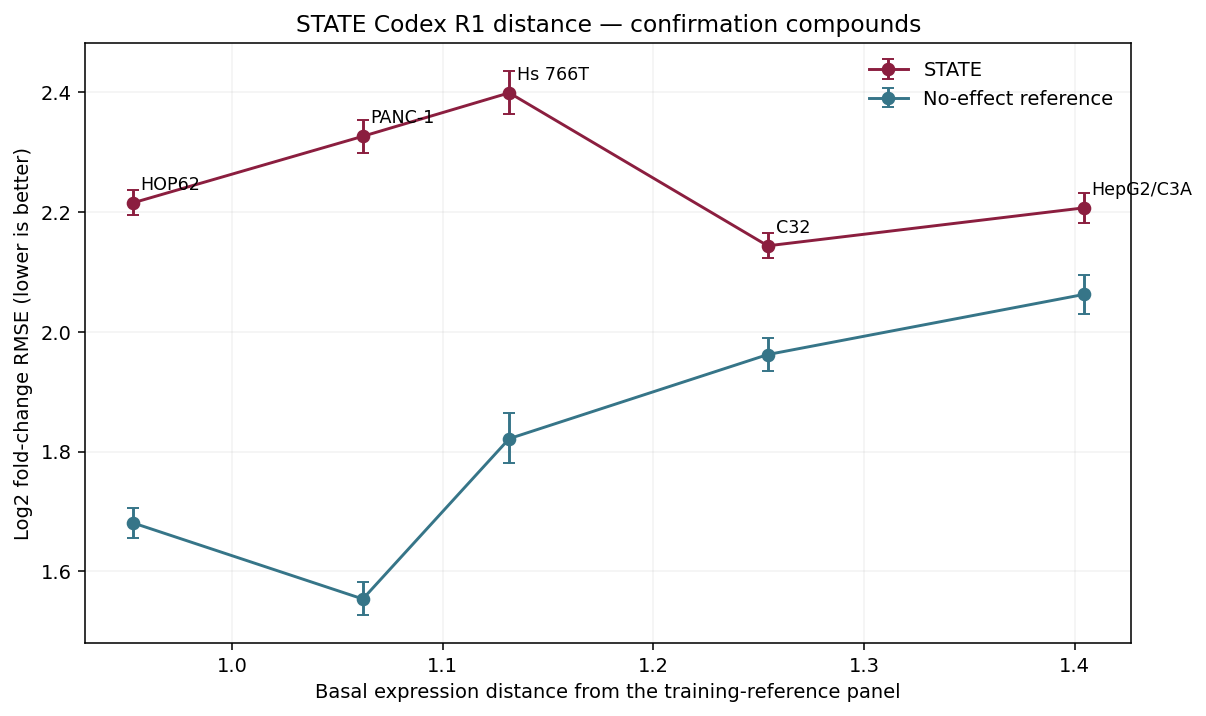

In [16]:
def context_spc(frame: pd.DataFrame, reps: int, seed: int) -> pd.DataFrame:
    compound_context = frame.groupby(["compound", "cell_line"], as_index=False).agg(
        state_lfc_rmse=("state_lfc_rmse", "mean"),
        identity_lfc_rmse=("identity_lfc_rmse", "mean"),
        distance=("distance", "first"),
        ccle_distance=("ccle_distance", "first"),
        n_conditions=("target", "nunique"),
    )
    compounds = sorted(compound_context["compound"].unique())
    rng = np.random.default_rng(seed)
    rows = []
    for cell, group in compound_context.groupby("cell_line"):
        indexed = group.set_index("compound")
        state_values = indexed.loc[compounds, "state_lfc_rmse"].to_numpy()
        reference_values = indexed.loc[compounds, "identity_lfc_rmse"].to_numpy()
        state_boot = np.empty(reps)
        reference_boot = np.empty(reps)
        for i in range(reps):
            sample = rng.integers(0, len(compounds), len(compounds))
            state_boot[i] = state_values[sample].mean()
            reference_boot[i] = reference_values[sample].mean()
        rows.append(
            {
                "cell_line": cell,
                "distance": group["distance"].iloc[0],
                "ccle_distance": group["ccle_distance"].iloc[0],
                "n_compounds": len(compounds),
                "n_conditions": int(group["n_conditions"].sum()),
                "state_rmse_mean": state_values.mean(),
                "state_rmse_ci_low": np.quantile(state_boot, 0.025),
                "state_rmse_ci_high": np.quantile(state_boot, 0.975),
                "identity_rmse_mean": reference_values.mean(),
                "identity_rmse_ci_low": np.quantile(reference_boot, 0.025),
                "identity_rmse_ci_high": np.quantile(reference_boot, 0.975),
            }
        )
    return pd.DataFrame(rows).sort_values("distance")

curve = context_spc(confirm, BOOTSTRAP_REPS, RANDOM_SEED)
display(curve)
curve_rho = float(spearmanr(curve.distance, curve.state_rmse_mean).statistic)
print('Distance versus STATE mean-error Spearman correlation:', curve_rho)

fig, ax = plt.subplots(figsize=(8.5, 5.0), layout='constrained')
for metric, label, color in [('state', 'STATE', '#8B1E3F'), ('identity', 'No-effect reference', '#367588')]:
    means = curve[f'{metric}_rmse_mean'].to_numpy()
    low = curve[f'{metric}_rmse_ci_low'].to_numpy()
    high = curve[f'{metric}_rmse_ci_high'].to_numpy()
    ax.errorbar(curve.distance, means, yerr=np.vstack([means-low, high-means]),
                marker='o', capsize=3, color=color, label=label)
for row in curve.itertuples():
    ax.annotate(row.cell_line, (row.distance, row.state_rmse_mean),
                xytext=(4, 7), textcoords='offset points', fontsize=9)
ax.set(xlabel='Basal expression distance from the training-reference panel',
       ylabel='Log2 fold-change RMSE (lower is better)',
       title='STATE Codex R1 distance — confirmation compounds')
ax.legend(frameon=False)
ax.grid(alpha=.15)
fig.savefig(OUTPUT_DIR / 'distance_curve.png', dpi=160)
figure_buffer = BytesIO()
fig.savefig(figure_buffer, format='png', dpi=140, bbox_inches='tight')
display(Image(data=figure_buffer.getvalue()))
plt.close(fig)


**Controls:** repeat the adjusted fit separately at each dose and after omitting each cell line; substitute independent CCLE distance, including a separate fit excluding the HepG2 proxy. Retain the full-panel distance scale in these subsets.

The quintile sensitivity is an **indicator adjustment**: bin reference error and cell counts into quintiles within the confirmation population, then add four indicator columns for each. Every row remains; it does not form matched pairs. The code below shows the exact binning used here.


In [17]:
sensitivity_rows = []
for dose, group in confirm.groupby('dose'):
    result = fit_within(group, 'state_lfc_rmse', CONTROLS)
    sensitivity_rows.append({'control': 'dose', 'subset': str(dose), **result})
for cell in sorted(confirm.cell_line.unique()):
    result = fit_within(confirm[confirm.cell_line.ne(cell)], 'state_lfc_rmse', CONTROLS)
    sensitivity_rows.append({'control': 'omit context', 'subset': cell, **result})
sensitivities = pd.DataFrame(sensitivity_rows)
display(sensitivities[['control', 'subset', 'estimate', 'se_cluster', 'n_rows', 'n_compounds']])

ccle_confirm = confirm.copy()
ccle_confirm['distance_z'] = ccle_confirm.ccle_distance_z
ccle_fit, _ = fit_with_interval(ccle_confirm, 'state_lfc_rmse', CONTROLS)
ccle_exact_fit, _ = fit_with_interval(ccle_confirm[~ccle_confirm.proxy_used], 'state_lfc_rmse', CONTROLS)
display(pd.DataFrame([
    {'control': 'CCLE including declared HepG2 proxy', **ccle_fit},
    {'control': 'CCLE excluding proxy context', **ccle_exact_fit},
])[['control', 'estimate', 'ci_low', 'ci_high', 'n_rows']])

quintile_rows = confirm.copy()
quintile_rows['effect_bin'], effect_edges = pd.qcut(quintile_rows.identity_lfc_rmse, 5, labels=False, retbins=True, duplicates='drop')
quintile_rows['cells_bin'], cell_edges = pd.qcut(quintile_rows.n_cells, 5, labels=False, retbins=True, duplicates='drop')
quintile_controls = []
for prefix, column in [('effect_q', 'effect_bin'), ('cells_q', 'cells_bin')]:
    for level in range(1, 5):
        name = f'{prefix}_{level}'
        quintile_rows[name] = quintile_rows[column].eq(level).astype(float)
        quintile_controls.append(name)
quintile_fit = fit_within(quintile_rows, 'state_lfc_rmse', quintile_controls)
print('Reference-error cutpoints:', effect_edges)
print('Cell-count cutpoints:', cell_edges)
print('Rows retained in quintile adjustment:', len(quintile_rows))
display(pd.DataFrame([quintile_fit]))
display(quintile_rows.groupby(['effect_bin', 'cells_bin', 'cell_line'], observed=True).size().unstack('cell_line', fill_value=0))


,control,subset,estimate,se_cluster,n_rows,n_compounds
0,dose,0.05,-0.152905,0.006052,1340,268
1,dose,0.5,-0.134063,0.008170,1340,268
2,dose,5.0,-0.159950,0.006809,1340,268
3,omit context,C32,-0.128584,0.005732,3216,268
4,omit context,HOP62,-0.269291,0.007472,3216,268
5,omit context,HepG2/C3A,-0.094577,0.004762,3216,268
6,omit context,Hs 766T,-0.085716,0.005954,3216,268
7,omit context,PANC-1,-0.159760,0.005212,3216,268


,control,estimate,ci_low,ci_high,n_rows
0,CCLE including declared HepG2 proxy,-0.129623,-0.139850,-0.118728,4020
1,CCLE excluding proxy context,-0.078860,-0.088116,-0.069602,3216


Reference-error cutpoints: [0.63415208 1.48635944 1.67803462 1.8821652  2.11718487 4.24588553]
Cell-count cutpoints: [1.0000e+00 8.3180e+02 1.4722e+03 2.2870e+03 3.5452e+03 5.7193e+04]
Rows retained in quintile adjustment: 4020


,estimate,se_cluster,p_one_sided,p_two_sided,n_rows,n_targets,n_compounds,controls
0,-0.127852,0.006395,1.0,6.565720e-89,4020,804,268,"[effect_q_1, effect_q_2, effect_q_3, effect_q_4, cells_q_1, cells_q_2, cells_q_3, cells_q_4]"


cell_line             C32  HOP62  HepG2/C3A  Hs 766T  PANC-1
effect_bin cells_bin                                        
0          2            0      0          0        0       1
           3            6     24         20       19      60
           4           37    171         19      149     298
1          1            0      0          1        0       0
           2            8     27         42       42      46
           3           80    160         36      102     151
           4           12     47          0       15      35
2          0            0      0          2        0       0
           1            9     21         71       40      26
           2          153    130         46       88      74
           3           30     64          2       14      21
           4            1      3          0        6       3
3          0            1      4         83       32       3
           1          162     79        135      114      33
           2           77     26          6       15      16
           3            3      2          0        2       4
           4            0      2          1        0       4
4          0          139     30        331      157      22
           1           80     11          9        8       5
           2            4      2          0        1       1
           3            2      0          0        0       1
           4            0      1          0        0       0

Visual checks below show independent-atlas agreement, the relationship between reference effect magnitude and STATE error, and the dose/context sensitivities. The sensitivity bars use **1.96 × compound-clustered standard errors**; the main curve and principal-fit intervals above use compound bootstrap intervals.


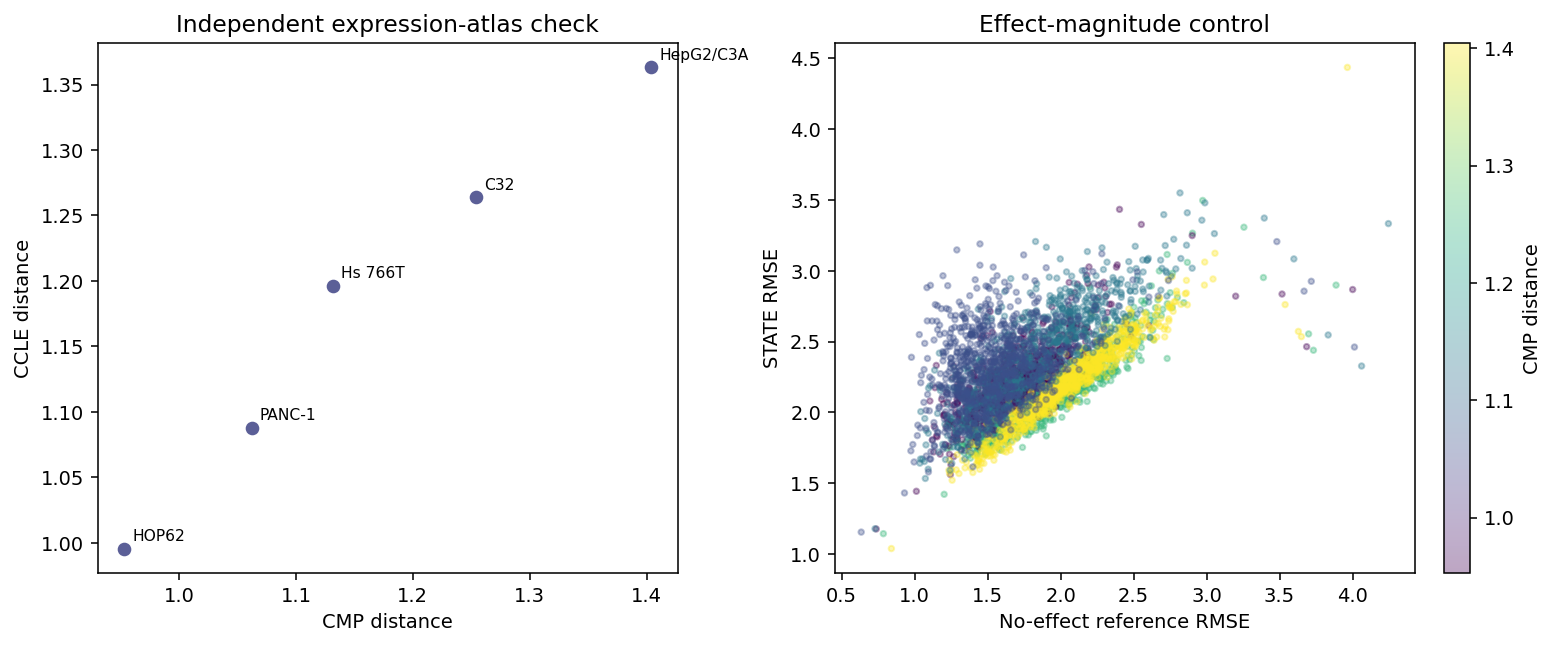

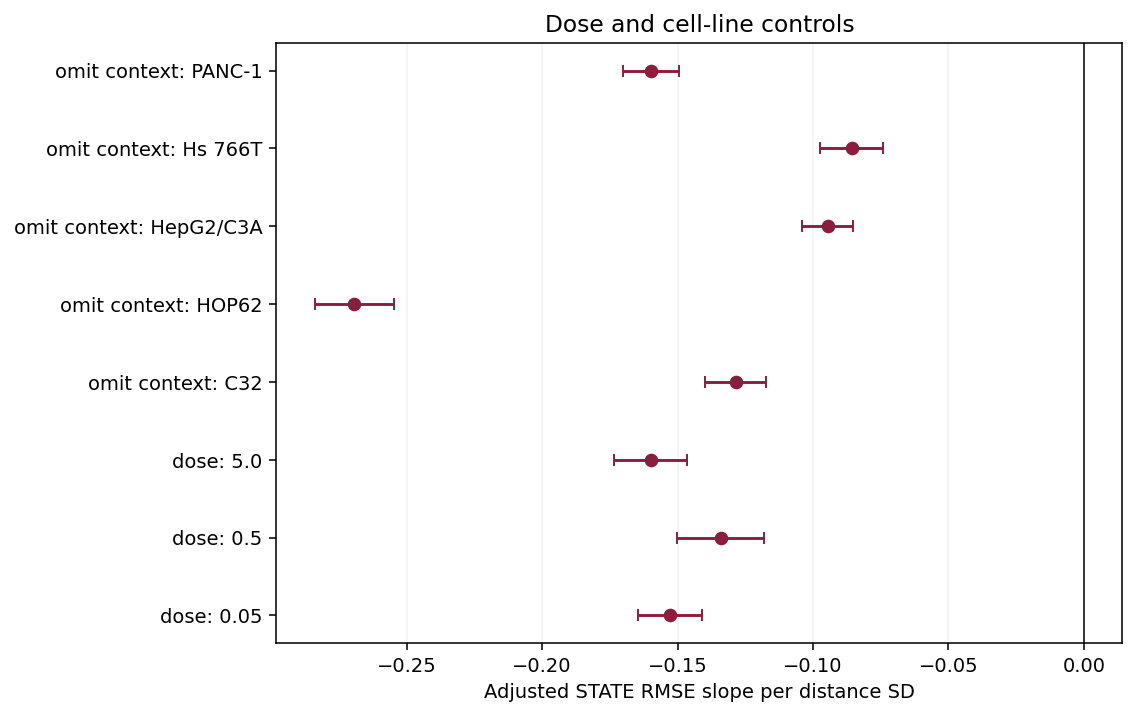

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout='constrained')
axes[0].scatter(atlas_check.distance_cmp, atlas_check.distance_ccle, color='#5B5F97')
for row in atlas_check.itertuples():
    axes[0].annotate(row.cell_line, (row.distance_cmp, row.distance_ccle),
                     xytext=(4, 4), textcoords='offset points', fontsize=8)
axes[0].set(xlabel='CMP distance', ylabel='CCLE distance', title='Independent expression-atlas check')
points = axes[1].scatter(confirm.identity_lfc_rmse, confirm.state_lfc_rmse,
                        c=confirm.distance, s=8, alpha=.35, cmap='viridis')
axes[1].set(xlabel='No-effect reference RMSE', ylabel='STATE RMSE', title='Effect-magnitude control')
fig.colorbar(points, ax=axes[1], label='CMP distance')
fig.savefig(OUTPUT_DIR / 'atlas_and_effect_controls.png', dpi=160)
buffer = BytesIO(); fig.savefig(buffer, format='png', dpi=140, bbox_inches='tight')
display(Image(data=buffer.getvalue())); plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5), layout='constrained')
positions = np.arange(len(sensitivities))
ax.errorbar(sensitivities.estimate, positions, xerr=1.96 * sensitivities.se_cluster,
            fmt='o', capsize=3, color='#8B1E3F')
ax.axvline(0, color='black', linewidth=.8)
ax.set_yticks(positions, sensitivities.control + ': ' + sensitivities.subset)
ax.set(xlabel='Adjusted STATE RMSE slope per distance SD', title='Dose and cell-line controls')
ax.grid(axis='x', alpha=.15)
fig.savefig(OUTPUT_DIR / 'dose_context_controls.png', dpi=160)
buffer = BytesIO(); fig.savefig(buffer, format='png', dpi=140, bbox_inches='tight')
display(Image(data=buffer.getvalue())); plt.close(fig)


## 6. What the agent decided, and why

**Decision: reject the proposed distance-related worsening.** The hypothesis was that STATE prediction error increases as a held-out cell line becomes more distant in baseline expression from the training-reference panel. The raw and adjusted STATE slopes are negative, and the quintile and independent-atlas controls retain that direction.

The table below summarizes the calculated slopes. Positive slopes indicate greater prediction error at greater distance; negative slopes indicate lower error. The decision follows these results and the confirmation curve in section 5.


In [19]:
calculated = {
    'STATE raw': fit_results[('confirmation', 'state_raw')]['estimate'],
    'STATE adjusted': fit_results[('confirmation', 'state_adjusted')]['estimate'],
    'Identity reference': fit_results[('confirmation', 'identity_raw')]['estimate'],
    'Quintile adjustment': quintile_fit['estimate'],
    'CCLE adjusted': ccle_fit['estimate'],
    'CCLE without proxy': ccle_exact_fit['estimate'],
}
slope_summary = pd.DataFrame([
    {'analysis': name, 'slope': value,
     'direction': 'Lower error at greater distance' if value < 0 else
                  'Higher error at greater distance' if value > 0 else 'No slope'}
    for name, value in calculated.items()
])
display(slope_summary)
main_slopes_negative = calculated['STATE raw'] < 0 and calculated['STATE adjusted'] < 0
control_slopes_negative = all(
    calculated[name] < 0
    for name in ['Quintile adjustment', 'CCLE adjusted', 'CCLE without proxy']
)
if main_slopes_negative and control_slopes_negative:
    decision = 'Reject the proposed distance-related worsening'
    print('Decision:', decision)
    print('Raw and adjusted STATE error slopes are negative; the quintile and')
    print('independent-atlas controls also show lower error at greater distance.')
else:
    decision = 'Inspect the calculated curve and controls before assigning a decision'
    print('Decision:', decision)
print('Context-mean curve Spearman correlation:', curve_rho)
print('Paired STATE-minus-reference slope:', paired_difference, '| 95% bootstrap CI:', paired_ci)


,analysis,slope,direction
0,STATE raw,-0.032213,Lower error at greater distance
1,STATE adjusted,-0.150035,Lower error at greater distance
2,Identity reference,0.163206,Higher error at greater distance
3,Quintile adjustment,-0.127852,Lower error at greater distance
4,CCLE adjusted,-0.129623,Lower error at greater distance
5,CCLE without proxy,-0.078860,Lower error at greater distance


Decision: Reject the proposed distance-related worsening
Raw and adjusted STATE error slopes are negative; the quintile and
independent-atlas controls also show lower error at greater distance.
Context-mean curve Spearman correlation: -0.49999999999999994
Paired STATE-minus-reference slope: -0.1954190936159045 | 95% bootstrap CI: [-0.2015688  -0.18916182]


Save the newly calculated tables and an execution record for inspection. These files are **outputs**; earlier cells do not read them. Running the notebook again recalculates all derived stages.


In [20]:
for filename, frame in {
    'cell_line_mapping.csv': mapping, 'primary_cmp_distances.csv': primary,
    'independent_ccle_distances.csv': independent, 'cell_counts.csv': cell_counts,
    'compound_eligibility.csv': eligibility.reset_index(), 'per_condition_scores.csv': conditions,
    'released_error_calculations.csv': scored_rows, 'regressions.csv': fits,
    'spc_table.csv': curve, 'dose_context_sensitivities.csv': sensitivities,
    'slope_summary.csv': slope_summary,
}.items():
    frame.to_csv(OUTPUT_DIR / filename, index=False)
(OUTPUT_DIR / 'axis_genes.txt').write_text('\n'.join(axis_genes) + '\n')
execution_record = {
    'completed': True, 'host': platform.node(), 'python': platform.python_version(),
    'elapsed_seconds': round(time.time() - STARTED, 3),
    'source_files': len(download_receipts), 'source_bytes': sum(row['bytes'] for row in SOURCES),
    'sources': download_receipts, 'custom_external_code_used': False,
    'derived_output_files_read_as_inputs': False, 'audit_specific_fine_tuning': False,
    'model_inference_performed': False, 'checkpoint': 'ST-HVG-Tahoe eval_best.ckpt zero-shot',
    'evaluation_feature_pairs': int(scored_rows.n_genes_lfc.sum()),
    'confirmation_rows': len(confirm), 'confirmation_compounds': int(confirm.compound.nunique()),
    'main_slopes_negative': bool(main_slopes_negative),
    'control_slopes_negative': bool(control_slopes_negative),
    'decision': decision,
    'bootstrap_repetitions': BOOTSTRAP_REPS, 'random_seed': RANDOM_SEED,
    'output_files': {name: sha256_file(OUTPUT_DIR / name) for name in [
        'cell_line_mapping.csv', 'primary_cmp_distances.csv', 'independent_ccle_distances.csv',
        'cell_counts.csv', 'compound_eligibility.csv', 'per_condition_scores.csv',
        'released_error_calculations.csv', 'regressions.csv', 'spc_table.csv',
        'dose_context_sensitivities.csv', 'slope_summary.csv', 'axis_genes.txt',
        'distance_curve.png', 'atlas_and_effect_controls.png', 'dose_context_controls.png',
    ]},
}
(OUTPUT_DIR / 'execution_record.json').write_text(json.dumps(execution_record, indent=2) + '\n')
print('Completed distance analysis on', execution_record['host'])
print('Elapsed seconds:', execution_record['elapsed_seconds'])
print('Calculated tables, figures and execution record:', OUTPUT_DIR)


Completed distance analysis on exxact05.broadinstitute.org
Elapsed seconds: 56.423
Calculated tables, figures and execution record: /ewsc/yektefai/spectra_runs/state_codex_r1_distance_inline_review_20261109/state_distance_outputs
